In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from sklearn.svm import SVC

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [2]:
def graficar_svm_lineal(
    modelo,
    X,
    y,
    titulo="Clasificador de soporte vectorial"
):
    
    plt.figure(figsize=(8, 6))
    
    for clase in np.unique(y):
        plt.scatter(
            X[y == clase, 0],
            X[y == clase, 1],
            label=f"Clase {clase}",
            s=70
        )
    
    x_min = X[:, 0].min() - 1
    x_max = X[:, 0].max() + 1
    
    y_min = X[:, 1].min() - 1
    y_max = X[:, 1].max() + 1
    
    xx = np.linspace(x_min, x_max, 300)
    yy = np.linspace(y_min, y_max, 300)
    
    YY, XX = np.meshgrid(yy, xx)
    
    grid = np.c_[XX.ravel(), YY.ravel()]
    
    Z = modelo.decision_function(grid)
    Z = Z.reshape(XX.shape)
    
    plt.contour(
        XX,
        YY,
        Z,
        levels=[-1, 0, 1],
        linestyles=["--", "-", "--"]
    )
    
    plt.scatter(
        modelo.support_vectors_[:, 0],
        modelo.support_vectors_[:, 1],
        s=180,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        label="Vectores de soporte"
    )
    
    plt.xlabel("$X_1$")
    plt.ylabel("$X_2$")
    plt.title(titulo)
    plt.legend()
    plt.show()

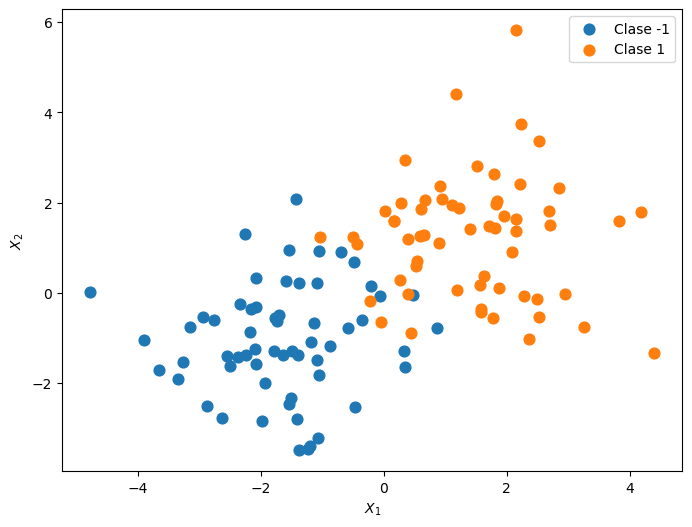

In [3]:
X, y = make_blobs(n_samples = 120, centers = [[-1.5,-1.0],[1.5,1.0]], cluster_std=1.25, random_state = 42)
y = np.where(y==0,-1,1)

plt.figure(figsize=(8,6))
for clase in np.unique(y):
    plt.scatter(X[y==clase, 0], X[y==clase,1], label = f"Clase {clase}", s=60)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.legend()
plt.show()

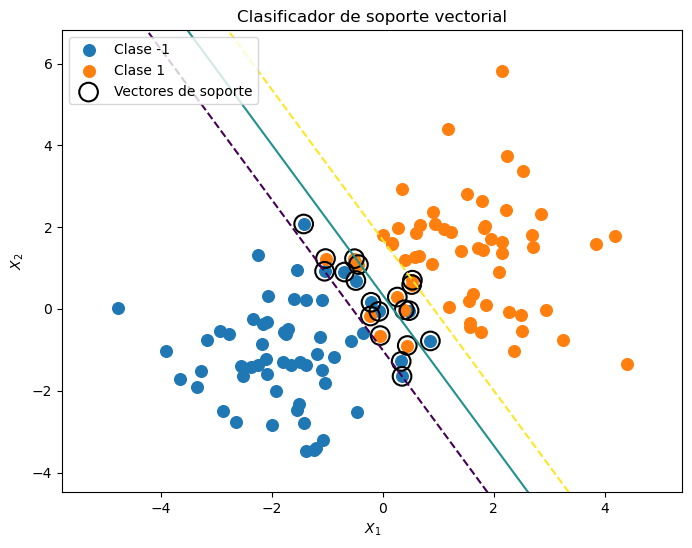

In [4]:
modelo_C1 = SVC(kernel = "linear", C = 1)
modelo_C1.fit(X,y)
graficar_svm_lineal(modelo_C1, X, y)

In [5]:
decision = modelo_C1.decision_function(X)
margen_funcional = y * decision

resultados = pd.DataFrame({
    "X1": X[:, 0],
    "X2": X[:,1],
    "Clase": y,
    "Decision": decision,
    "y_f(x)": margen_funcional
})

resultados.head()

,X1,X2,Clase,Decision,y_f(x)
0,-1.701607,-0.494936,-1,-2.944531,2.944531
1,-1.774590,-0.553609,-1,-3.087797,3.087797
2,0.441508,-0.893559,1,-0.311709,-0.311709
3,-1.543390,-2.460848,-1,-4.186999,4.186999
4,-1.048255,0.922546,-1,-0.999970,0.999970


In [6]:
def posicion_margen(valor):
    if valor < 0:
        return "Mal clasificada"
    elif valor <1:
        return "Dentro del margen"
    else:
        return "Sobre o fuera del margen"

In [7]:
resultados["Posicion"] = (resultados["y_f(x)"].apply(posicion_margen))

In [8]:
resultados["Posicion"].value_counts()

Posicion
Sobre o fuera del margen    101
Dentro del margen            11
Mal clasificada               8
Name: count, dtype: int64

In [9]:
valores_C = [0.01,0.1,1,10,100]
accuracy = []
n_vect = []
dentro_margen = []
for C in valores_C:
    modelo = SVC(kernel = "linear", C= C)
    modelo.fit(X,y)
    pred = modelo.predict(X)
    
    
    acu = accuracy_score(y,pred)
    accuracy.append(acu)
    
    
    nvec = modelo.support_
    n_vect.append(len(nvec))
    
    decision = modelo.decision_function(X)
    margen_funcional = y * decision

    
    dentro = []
    for x in margen_funcional:
        if x < 1:
            dentro.append(1)
    dentro_margen.append(len(dentro))
    
df = pd.DataFrame({"Valores C": valores_C,"Accuracy": accuracy,"n_vec": n_vect,"Num dentro del margen": dentro_margen}
                 )
df
    #graficar_svm_lineal(modelo, X, y, titulo = f"Clasificador lineal C={C}")

,Valores C,Accuracy,n_vec,Num dentro del margen
0,0.01,0.941667,59,58
1,0.10,0.950000,29,27
2,1.00,0.933333,20,19
3,10.00,0.950000,17,16
4,100.00,0.950000,16,15


In [10]:
X_train, X_test,y_train, y_test = train_test_split(X,y, test_size = 0.3, stratify = y, random_state = 42)

accuracy = []
n_vect = []
dentro_margen = []
accuracy_test = []
for C in valores_C:
    modelo = SVC(kernel = "linear", C= C)
    modelo.fit(X_train,y_train)
    pred = modelo.predict(X)
    
    
    acu = accuracy_score(y,pred)
    accuracy.append(acu)

    pred_test = modelo.predict(X_test)
    acu_test = accuracy_score(y_test,pred_test)
    accuracy_test.append(acu_test)
    
    
    nvec = modelo.support_
    n_vect.append(len(nvec))
    
    decision = modelo.decision_function(X)
    margen_funcional = y * decision

    
    dentro = []
    for x in margen_funcional:
        if x < 1:
            dentro.append(1)
    dentro_margen.append(len(dentro))
    
df = pd.DataFrame({"Valores C": valores_C,"Accuracy entrenamiendo": accuracy,"Accuracy test": accuracy_test,"n_vec": n_vect,"Num dentro del margen": dentro_margen}
                 )
df

,Valores C,Accuracy entrenamiendo,Accuracy test,n_vec,Num dentro del margen
0,0.01,0.908333,0.833333,46,63
1,0.10,0.941667,0.888889,20,32
2,1.00,0.933333,0.888889,11,18
3,10.00,0.941667,0.888889,9,14
4,100.00,0.941667,0.888889,8,13


In [11]:
X_desescalado = X.copy()
X_desescalado[:,1] = (1000 * X_desescalado[:,1])
df = pd.DataFrame(X_desescalado, columns=["X_1","X_2"]).describe()
df

,X_1,X_2
count,120.000000,120.000000
mean,-0.102725,96.718547
std,1.918775,1724.595599
min,-4.774681,-3484.461143
25%,-1.556090,-1187.641213
50%,-0.058830,-33.279743
75%,1.560914,1428.095042
max,4.393323,5815.914363


In [12]:
modelo_sin_escalar = SVC(kernel = "linear", C=1)
modelo_sin_escalar.fit(X_desescalado, y)
modelo_sin_escalar.coef_

array([[1.53345981e+00, 1.00536765e-03]])

In [13]:
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_desescalado)
pd.DataFrame(X_escalado, columns = ['X_1','X_2']).describe()

,X_1,X_2
count,1.200000e+02,1.200000e+02
mean,-2.220446e-17,1.850372e-17
std,1.004193e+00,1.004193e+00
min,-2.445074e+00,-2.085240e+00
25%,-7.606205e-01,-7.478535e-01
50%,2.297229e-02,-7.569505e-02
75%,8.706670e-01,7.752303e-01
max,2.353012e+00,3.330158e+00


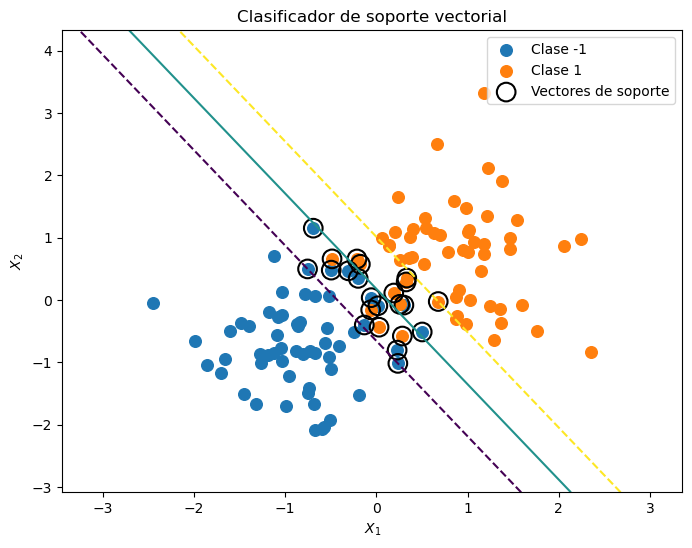

In [14]:
modelo_escalado = SVC(kernel = "linear", C=1)
modelo_escalado.fit(X_escalado, y)
graficar_svm_lineal(modelo_escalado, X_escalado,y)

In [15]:
X_train,X_test, y_train,y_test = train_test_split(X_desescalado, y, test_size = 0.3, random_state = 42, stratify = y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modelo_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "linear", C=1))
    ]
    
)

modelo_pipeline.fit(X_train, y_train)
pred_train = modelo_pipeline.predict(X_train)
pred_test = modelo_pipeline.predict(X_test)
accuracy_score(y_train, pred_train)



0.9642857142857143

In [16]:
accuracy_score(y_test, pred_test)

0.8888888888888888

# Ejercicios

## 13.19.1 Ejercicio 1. Observaciones y margen
Utilizando modelo_C1, calcula


para todas las observaciones.

Encuentra:

cuántas están mal clasificadas;

RESPUESTA: 0

cuántas están correctamente clasificadas pero dentro del margen;

RESPUESTA:2

cuántas están sobre o fuera del margen.

RESPUESTA: 118

Posicion
Sobre o fuera del margen    118
Dentro del margen             2
Name: count, dtype: int64


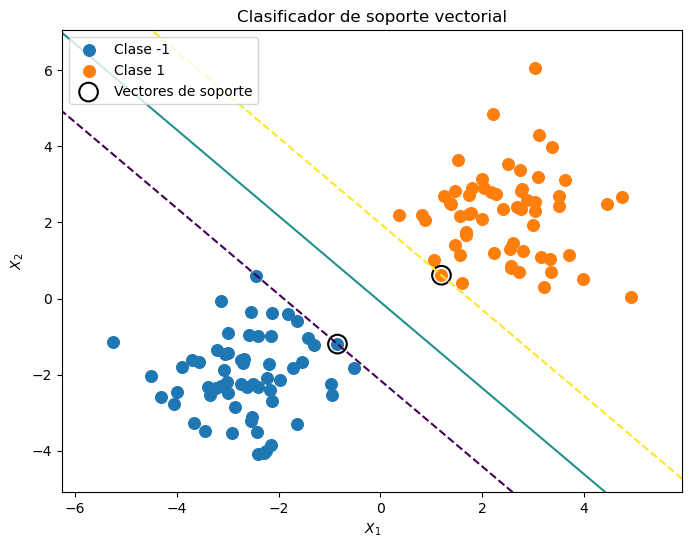

In [21]:
X, y = make_blobs(n_samples = 120, centers = [[-2.5,-2.0],[2.5,2.0]], cluster_std=1.05, random_state = 42)
y = np.where(y==0,-1,1)
modelo_C1 = SVC(kernel = "linear", C = 3)
modelo_C1.fit(X,y)

decision = modelo_C1.decision_function(X)
margen_funcional = y * decision

resultados = pd.DataFrame({
    "X1": X[:, 0],
    "X2": X[:,1],
    "Clase": y,
    "Decision": decision,
    "y_f(x)": margen_funcional
})

resultados["Posicion"] = (resultados["y_f(x)"].apply(posicion_margen))
print(resultados["Posicion"].value_counts())
graficar_svm_lineal(modelo_C1,X,y)


## 13.19.2 Ejercicio 2. Efecto de un valor extremo de C
Ajusta dos modelos:


y


Compara:

frontera;

Respuesta: es mas amplia para el c pequeño

margen;

Respuesta: es mayor para el valor c pequeño/

RESPUESTA: El margen es mucho mas amplio para el del valor c pequeño

número de vectores de soporte;

RESPUESTA: Igual es mucho mayor el numero de vectores de soporte para un valor c pequeño

exactitud de entrenamiento.

RESPUESTA: el acuraccy es de 1

No selecciones un modelo únicamente a partir de estas cantidades. El objetivo es interpretar cómo cambia el ajuste.

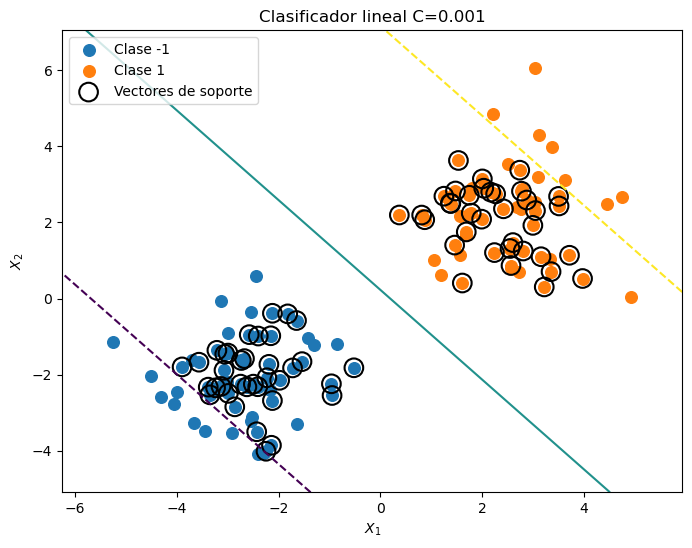

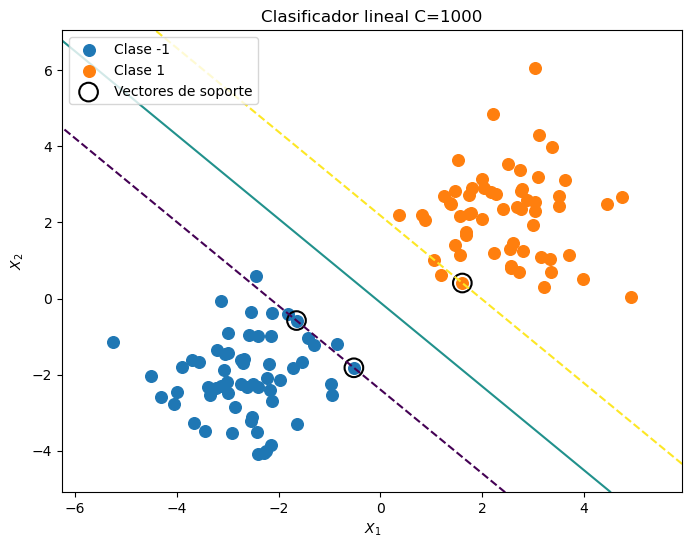

,Valores C,Accuracy entrenamiendo,Accuracy test,n_vec,Num dentro del margen
0,0.001,1.0,1.0,72,103
1,1000.000,1.0,1.0,3,6


In [18]:
X_train, X_test,y_train, y_test = train_test_split(X,y, test_size = 0.3, stratify = y, random_state = 42)

accuracy = []
n_vect = []
dentro_margen = []
accuracy_test = []
valores_C = [0.001,1000]
for C in valores_C:
    modelo = SVC(kernel = "linear", C= C)
    modelo.fit(X_train,y_train)
    pred = modelo.predict(X)
    
    
    acu = accuracy_score(y,pred)
    accuracy.append(acu)

    pred_test = modelo.predict(X_test)
    acu_test = accuracy_score(y_test,pred_test)
    accuracy_test.append(acu_test)
    
    
    nvec = modelo.support_
    n_vect.append(len(nvec))
    
    decision = modelo.decision_function(X)
    margen_funcional = y * decision

    
    dentro = []
    for x in margen_funcional:
        if x < 1:
            dentro.append(1)
    dentro_margen.append(len(dentro))
    graficar_svm_lineal(modelo, X, y, titulo = f"Clasificador lineal C={C}")
    
df = pd.DataFrame({"Valores C": valores_C,"Accuracy entrenamiendo": accuracy,"Accuracy test": accuracy_test,"n_vec": n_vect,"Num dentro del margen": dentro_margen}
                 )


df


## 13.19.3 Ejercicio 3. Cambiar artificialmente la escala
A partir de X, crea un nuevo conjunto donde


mientras que 
 permanece sin cambios.

Ajusta:

una SVM sin escalamiento;

una SVM dentro de un Pipeline con StandardScaler.

Compara los resultados.

Ambos resultados son iguales en el test


In [19]:
X_modificado = X.copy()
X_modificado[:,0] = 100*X_modificado[:,0]

Xm_train,Xm_test,y_train, y_test = train_test_split(X_modificado,y, test_size = 0.3, stratify = y, random_state = 42)

svm_ns = SVC()
svm_ns.fit(Xm_train,y_train)
y_ns = svm_ns.predict(Xm_test)

modelo_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "linear", C=1))
    ]
    
)
modelo_pipeline.fit(Xm_train,y_train)
y_pipe = modelo_pipeline.predict(Xm_test)

print("accuracy no escaldo ", accuracy_score(y_test,y_ns))
print("accuracy con modelo pipeline ", accuracy_score(y_test,y_pipe) )

accuracy no escaldo  1.0
accuracy con modelo pipeline  1.0
